In [1]:
import pandas as pd
import numpy as np

questions before analysis :
1. What are the top job titles, companies, and locations?
2. Which job type has the most postings?
3. Which months and years have the highest job postings?
4. What are the minimum, maximum, and average salaries for job roles, and are there any zero or unusual salary values?
5. Is there a significant difference in maximum salaries between full-time and contract jobs?

understanding data :

In [2]:
jobs=pd.read_csv('/content/CodeAlpha_JobData_Mega (2).csv')

In [3]:
jobs.shape

(1547, 10)

In [4]:
jobs.columns

Index(['title', 'company', 'location', 'job_type', 'min_amount', 'max_amount',
       'date_posted', 'description', 'job_url', 'site'],
      dtype='object')

In [5]:
jobs.dtypes

,0
title,object
company,object
location,object
job_type,object
min_amount,float64
max_amount,float64
date_posted,object
description,object
job_url,object
site,object


In [6]:
jobs.head()

,title,company,location,job_type,min_amount,max_amount,date_posted,description,job_url,site
0,Senior Data Analyst,EXCEL EARTHINGS,"KL, India",fulltime,25000.0,45000.0,2026-10-10,* Perform exploratory data analysis to uncover...,https://in.indeed.com/viewjob?jk=95ac584799dd49ec,indeed
1,Data Analyst,Rajdeep Plastic (I) PVT LTD,"MH, India",fulltime,30000.0,35000.0,2026-10-09,**JOB DESCRIPTION – DATA ANALYST** **Designa...,https://in.indeed.com/viewjob?jk=6214d192d4d80774,indeed
2,Process Coordinator (Data Analyst / MIS),Techswarm,"DL, India",fulltime,22000.0,28000.0,2026-10-09,**Search and collect data from different onlin...,https://in.indeed.com/viewjob?jk=f83f20b1af1190f8,indeed
3,Senior Data Analyst,Cygnuss Agro,"MP, India",fulltime,50000.0,166000.0,2026-10-08,Data Analyst Location: Indore Experience: 3–...,https://in.indeed.com/viewjob?jk=9db0e5f3bfdea389,indeed
4,Workforce Management Data Analyst,Porch Group,"Remote, India",fulltime,1068800.0,1496300.0,2026-10-08,Porch Group is a leading vertical software and...,https://in.indeed.com/viewjob?jk=af7a999b9485d14f,indeed


In [7]:
jobs.sample()

,title,company,location,job_type,min_amount,max_amount,date_posted,description,job_url,site
387,Senior Accountant,UrbanSkinz,"BR, India",fulltime,30000.0,35000.0,2026-09-22,Senior Accountant – Job Description Location:...,https://in.indeed.com/viewjob?jk=bcec64da5920c577,indeed


In [8]:
jobs.tail()

,title,company,location,job_type,min_amount,max_amount,date_posted,description,job_url,site
1542,Business Development Executive,PinnacleU,"HR, India",fulltime,450000.0,500000.0,2026-03-19,Position: Business Development Executive Loca...,https://in.indeed.com/viewjob?jk=77307768dc47ad26,indeed
1543,Business Development Executive,Kriscent Techno Hub,"RJ, India",fulltime,600000.0,600000.0,2026-02-27,Responsible for researching and identifying sa...,https://in.indeed.com/viewjob?jk=fde5bcb3bf3b2065,indeed
1544,Business Development Executive,WPoets Technology,"MH, India",fulltime,30000.0,50000.0,2026-02-27,"**Role:** Marketing & Sales **Salary:** ₹30,0...",https://in.indeed.com/viewjob?jk=28a93c72f149a490,indeed
1545,Business Development Executive / Pre-sales Expert,ToXSL Technologies,"PB, India",fulltime,300000.0,800000.0,2026-02-26,"* Location: Mohali, India * Experience: 1-4 Ye...",https://in.indeed.com/viewjob?jk=2c66b64334dc2f21,indeed
1546,Business Development Executive/ Lead Generatio...,Innofied,"WB, India",fulltime,400000.0,600000.0,2026-02-19,**Job Information** ------------------- * Dat...,https://in.indeed.com/viewjob?jk=6c22c89034a998f0,indeed


In [9]:
jobs.sample(5)

,title,company,location,job_type,min_amount,max_amount,date_posted,description,job_url,site
1398,Senior Graphic Designer,Smart tech,"GJ, India",fulltime,35000.0,50342.2,2026-10-08,"* Design stunning graphics for packaging, prin...",https://in.indeed.com/viewjob?jk=7786f7d3dbf88e7c,indeed
1220,Network Engineer,G3 Renewables,"KL, India",fulltime,35000.0,40000.0,2026-09-14,"Experience: 2–5 Years Location: Kochi, Keral...",https://in.indeed.com/viewjob?jk=7a9619a45f715126,indeed
457,AI Engineer,CogniAI Advanced Research Solutions Private Li...,"TN, India",fulltime,50000.0,150000.0,2026-07-18,AI Engineer **Location:** India **Experienc...,https://in.indeed.com/viewjob?jk=ceb6d35eeaa7ee40,indeed
1490,Business Development Executive (BDE),Hiring Saathi,"WB, India",fulltime,350000.0,480000.0,2026-10-05,Business Development Executive (BDE) **Locati...,https://in.indeed.com/viewjob?jk=e3b48d71c638f2dd,indeed
686,Shopify Manager,Soni Sapphire,"DL, India",fulltime,30000.0,50000.0,2026-09-18,**Position Details** **Job Title:** Shopify M...,https://in.indeed.com/viewjob?jk=db3610b2c70f94fc,indeed


In [10]:
jobs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1547 entries, 0 to 1546
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   title        1547 non-null   object 
 1   company      1547 non-null   object 
 2   location     1547 non-null   object 
 3   job_type     1547 non-null   object 
 4   min_amount   1547 non-null   float64
 5   max_amount   1547 non-null   float64
 6   date_posted  1547 non-null   object 
 7   description  1547 non-null   object 
 8   job_url      1547 non-null   object 
 9   site         1547 non-null   object 
dtypes: float64(2), object(8)
memory usage: 121.0+ KB


Data cleaning:--

In [11]:
jobs.isnull().sum()

,0
title,0
company,0
location,0
job_type,0
min_amount,0
max_amount,0
date_posted,0
description,0
job_url,0
site,0


In [12]:
#duplicates checking:
jobs.duplicated().sum()

np.int64(0)

In [13]:
jobs['job_type'].value_counts()

,count
job_type,
fulltime,1446
contract,33
"fulltime, contract",30
"parttime, fulltime",10
"fulltime, internship",7
internship,6
parttime,5
"parttime, contract",3
"contract, internship",2


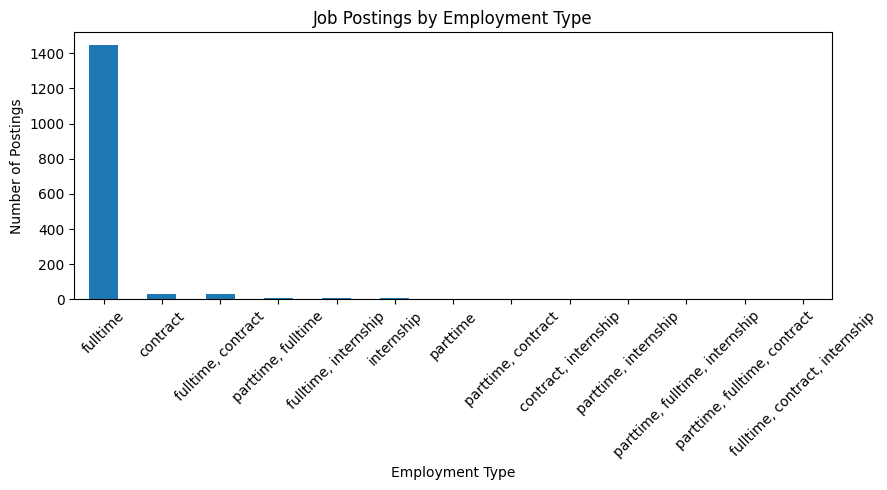

In [14]:
import matplotlib.pyplot as plt

jobs['job_type'].value_counts().plot(kind='bar', figsize=(9, 5))
plt.title('Job Postings by Employment Type')
plt.xlabel('Employment Type')
plt.ylabel('Number of Postings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
jobs['full_time'] = jobs['job_type'].str.contains(
    'fulltime', case=False, na=False
).astype(int)

jobs['part_time'] = jobs['job_type'].str.contains(
    'parttime', case=False, na=False
).astype(int)

jobs['contract'] = jobs['job_type'].str.contains(
    'contract', case=False, na=False
).astype(int)

jobs['internship'] = jobs['job_type'].str.contains(
    'internship', case=False, na=False
).astype(int)

In [16]:
jobs.drop(columns=['job_type'],inplace=True)

In [17]:
jobs.head()

,title,company,location,min_amount,max_amount,date_posted,description,job_url,site,full_time,part_time,contract,internship
0,Senior Data Analyst,EXCEL EARTHINGS,"KL, India",25000.0,45000.0,2026-10-10,* Perform exploratory data analysis to uncover...,https://in.indeed.com/viewjob?jk=95ac584799dd49ec,indeed,1,0,0,0
1,Data Analyst,Rajdeep Plastic (I) PVT LTD,"MH, India",30000.0,35000.0,2026-10-09,**JOB DESCRIPTION – DATA ANALYST** **Designa...,https://in.indeed.com/viewjob?jk=6214d192d4d80774,indeed,1,0,0,0
2,Process Coordinator (Data Analyst / MIS),Techswarm,"DL, India",22000.0,28000.0,2026-10-09,**Search and collect data from different onlin...,https://in.indeed.com/viewjob?jk=f83f20b1af1190f8,indeed,1,0,0,0
3,Senior Data Analyst,Cygnuss Agro,"MP, India",50000.0,166000.0,2026-10-08,Data Analyst Location: Indore Experience: 3–...,https://in.indeed.com/viewjob?jk=9db0e5f3bfdea389,indeed,1,0,0,0
4,Workforce Management Data Analyst,Porch Group,"Remote, India",1068800.0,1496300.0,2026-10-08,Porch Group is a leading vertical software and...,https://in.indeed.com/viewjob?jk=af7a999b9485d14f,indeed,1,0,0,0


The original job_type column was removed after creating four separate columns: full_time, part_time, contract, and internship. These columns make job type analysis easier.

In [18]:
jobs['date_posted'] = pd.to_datetime(jobs['date_posted'], errors='coerce')

print(jobs['date_posted'].dtype)
print(sorted(jobs['date_posted'].dt.year.dropna().unique()))

datetime64[ns]
[np.int32(2025), np.int32(2026)]


In [19]:
jobs.describe()

,min_amount,max_amount,date_posted,full_time,part_time,contract,internship
count,1.547000e+03,1.547000e+03,1547,1547.000000,1547.000000,1547.000000,1547.000000
mean,3.052287e+05,5.374324e+05,2026-08-31 15:36:25.132514816,0.967033,0.014221,0.045249,0.012282
min,0.000000e+00,0.000000e+00,2025-01-21 00:00:00,0.000000,0.000000,0.000000,0.000000
25%,3.000000e+04,4.524837e+04,2026-09-10 00:00:00,1.000000,0.000000,0.000000,0.000000
50%,6.000000e+04,9.000000e+04,2026-09-23 00:00:00,1.000000,0.000000,0.000000,0.000000
75%,4.000000e+05,7.000000e+05,2026-10-04 00:00:00,1.000000,0.000000,0.000000,0.000000
max,7.500000e+06,4.800000e+07,2026-10-10 00:00:00,1.000000,1.000000,1.000000,1.000000
std,5.480438e+05,1.470604e+06,NaN,0.178608,0.118439,0.207917,0.110176


doubt in max_amount is equal to zero in how many rows

In [20]:
(jobs['max_amount'] == 0).sum()

np.int64(3)

In [21]:
jobs[jobs['max_amount']==0]

,title,company,location,min_amount,max_amount,date_posted,description,job_url,site,full_time,part_time,contract,internship
46,Data Scientist/Analyst,Sumeru,"Remote, India",0.0,0.0,2026-02-27,**Job Title:- Data Scientist/Data Analyst** *...,https://in.indeed.com/viewjob?jk=2fc74bdc846f990a,indeed,1,0,0,0
566,Frontend Developer,Munjal Chakraborty Softwares And Media Pvt Ltd,"HR, India",0.0,0.0,2025-01-21,We are looking for a front-end developer who i...,https://in.indeed.com/viewjob?jk=156561e18acfbecd,indeed,1,0,0,0
1260,Database Administrator,HashStudioz Technologies Pvt Ltd,"UP, India",0.0,0.0,2025-01-21,Responsibilities:- * Responsible for providin...,https://in.indeed.com/viewjob?jk=4353650f1c4a7068,indeed,1,0,0,0


Three job postings have zero minimum and maximum salary values. These records are retained until the reason for the zero values can be verified.

In [22]:
salary_jobs = jobs[
    ~((jobs['min_amount'] == 0) & (jobs['max_amount'] == 0))
].copy()

print("Zero salary rows in jobs:",
      ((jobs['min_amount'] == 0) & (jobs['max_amount'] == 0)).sum())

print("Zero salary rows in salary_jobs:",
      ((salary_jobs['min_amount'] == 0) & (salary_jobs['max_amount'] == 0)).sum())

Zero salary rows in jobs: 3
Zero salary rows in salary_jobs: 0


Number of job titles available in dataset

In [23]:
jobs['title'].nunique()

750

EDA

1.Job title analyis
top 10 job titles in the dataset

In [24]:
jobs['title'].value_counts().sort_values(ascending=False).head(10)

,count
title,
Graphic Designer,63
Senior Accountant,62
HR Manager,45
Project Manager,41
Full Stack Developer,38
Business Development Executive (BDE),32
Business Analyst,29
Content Writer,29
Marketing Manager,27


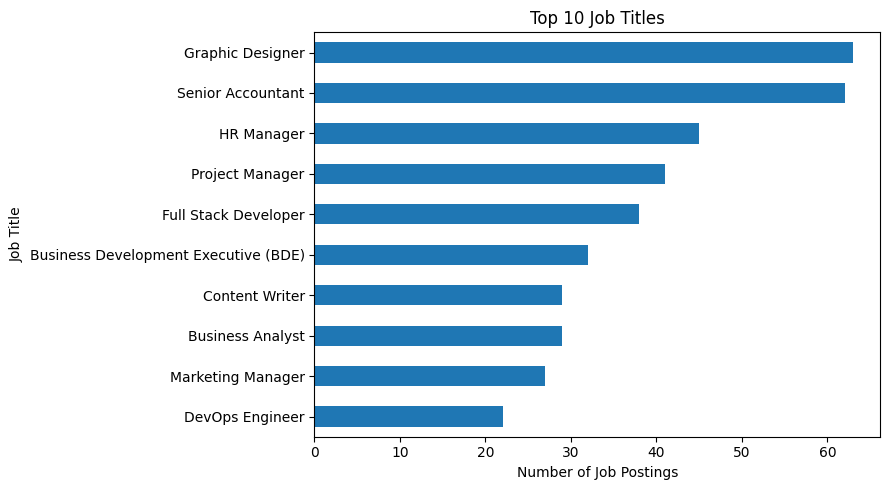

In [25]:
top_titles = jobs['title'].value_counts().head(10)
top_titles.sort_values().plot(kind='barh', figsize=(9, 5))
plt.title('Top 10 Job Titles')
plt.xlabel('Number of Job Postings')
plt.ylabel('Job Title')
plt.tight_layout()
plt.show()

2.Company analysis-- top 10companies

In [26]:
jobs['company'].value_counts().sort_values(ascending=False).head(10)

,count
company,
PinnacleU,13
Skyleaf Consultants,9
Technology Next,9
gHRig People Solutions,8
SoftMaji InfoTech,6
KSNR SERVICES (EdRex Learning),6
Hanumant Technology Pvt. Ltd.,5
Shivkan Business Services,4
Mograsys technologies,4


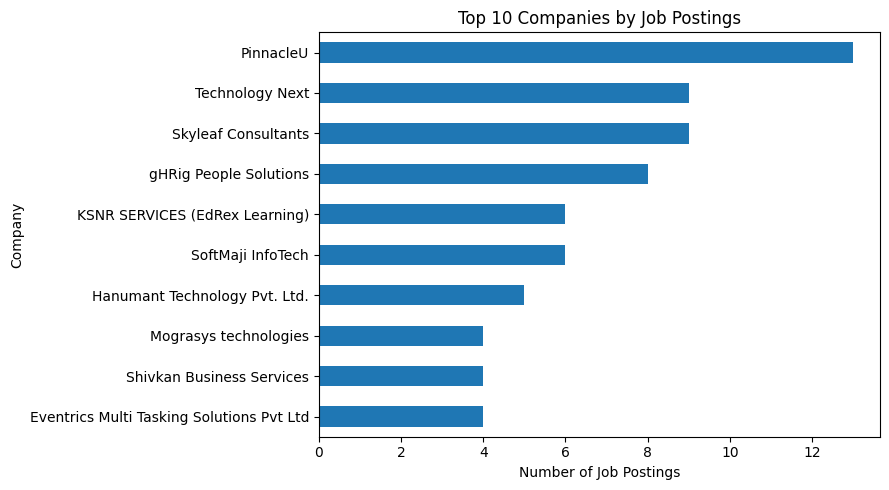

In [27]:
top_companies = jobs['company'].value_counts().head(10)
top_companies.sort_values().plot(kind='barh', figsize=(9, 5))
plt.title('Top 10 Companies by Job Postings')
plt.xlabel('Number of Job Postings')
plt.ylabel('Company')
plt.tight_layout()
plt.show()

LOCATION ANALYSIS

3.location analysis:
which locations has the heights number of job listing

In [28]:
jobs['location'].value_counts().head(10)

,count
location,
"MH, India",222
"DL, India",180
"UP, India",163
"Remote, India",128
"KA, India",121
"TN, India",117
"HR, India",87
"KL, India",75
"GJ, India",72


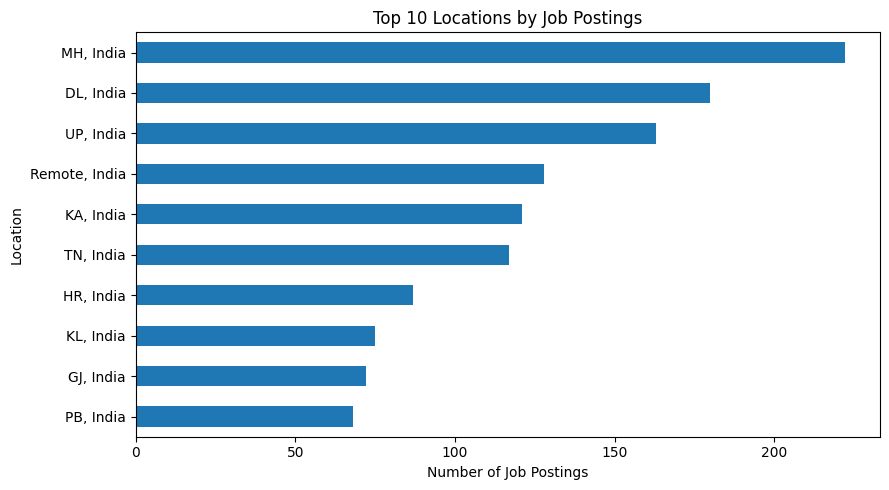

In [29]:
top_locations = jobs['location'].value_counts().head(10)
top_locations.sort_values().plot(kind='barh', figsize=(9, 5))
plt.title('Top 10 Locations by Job Postings')
plt.xlabel('Number of Job Postings')
plt.ylabel('Location')
plt.tight_layout()
plt.show()

Salary analysis based on location

In [30]:


location_salary = (
    jobs.groupby('location')['max_amount']
    .sum()
    .sort_values(ascending=False)
)


print(location_salary.head(10))


location
Remote, India    1.643063e+08
MH, India        1.383762e+08
KA, India        1.025336e+08
UP, India        6.244984e+07
DL, India        6.012414e+07
TN, India        5.661792e+07
HR, India        5.603543e+07
TS, India        3.620556e+07
RJ, India        2.866677e+07
GJ, India        2.325325e+07
Name: max_amount, dtype: float64


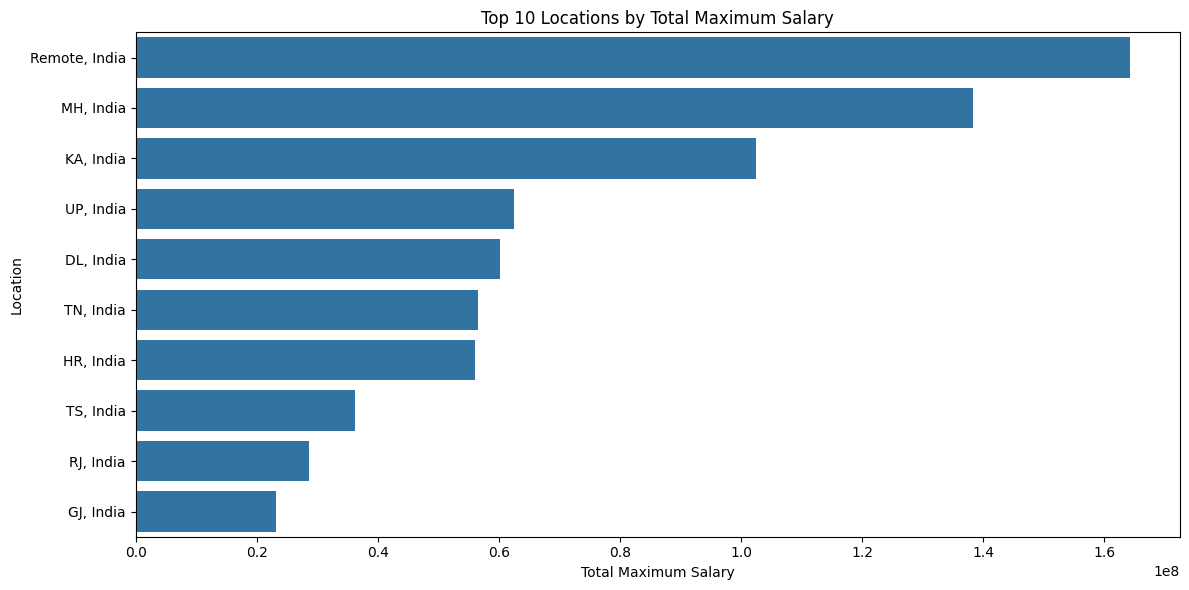

In [31]:
#visulatization:

import matplotlib.pyplot as plt
import seaborn as sns

top_locations = location_salary.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=top_locations.values,
    y=top_locations.index
)

plt.title('Top 10 Locations by Total Maximum Salary')
plt.xlabel('Total Maximum Salary')
plt.ylabel('Location')
plt.tight_layout()
plt.show()


ANALSING JOB TREND

In [32]:
jobs['date_posted'].dt.year.value_counts().sort_index()

,count
date_posted,
2025,25
2026,1522


Q2. Which months have the highest number of job postings in the collected dataset?

In [33]:
jobs['month'] = jobs['date_posted'].dt.month_name()

jobs['month'].value_counts().reindex([
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
], fill_value=0).sort_values(ascending=False)

,count
month,
September,700
October,496
July,116
August,101
June,73
February,20
January,18
March,13
May,4


Q3. How does the monthly distribution of job postings differ between 2025 and 2026?

In [34]:
monthly_yearly = jobs.groupby([
    jobs['date_posted'].dt.year,
    jobs['date_posted'].dt.month
]).size().unstack(fill_value=0)

monthly_yearly.columns = pd.to_datetime(
    monthly_yearly.columns, format='%m'
).month_name()

monthly_yearly

date_posted,January,February,March,April,May,June,July,August,September,October,November,December
date_posted,,,,,,,,,,,,
2025,17,0,0,0,0,0,2,1,1,1,1,2
2026,1,20,13,3,4,73,114,100,699,495,0,0


**Conclusion:** Most job postings in the dataset are from September and October 2026. The results may depend on how and when the data was collected.

ANALSIS of JOB TYPES

Which job type has the highest number of job postings in the dataset?

In [35]:
job_type_counts = jobs[['full_time', 'part_time', 'contract', 'internship']].sum()

print(job_type_counts)

full_time     1496
part_time       22
contract        70
internship      19
dtype: int64


Which job title has the highest number of job internship?

In [36]:

internship = jobs.groupby('title')['internship'].sum().sort_values(ascending=False)

internship = internship[internship> 0]

print(internship)

title
Data Science Intern                                 3
Graphic Designer                                    2
Python Developer Intern (AI / ML)                   1
Python Automation & Data Science Intern             1
GEN AI INTERNSHIP                                   1
Content Writer                                      1
Proxmox Linux Administrator (VDI Infrastructure)    1
AI Engineering Trainer                              1
Sr. Laravel Developers                              1
UI/UX Designer                                      1
Finance Research Analyst Intern                     1
Data Scientist                                      1
Machine Learning Intern                             1
Financial Analyst Intern                            1
Data Science & AI Internship                        1
Data / Research Analyst                             1
Name: internship, dtype: int64


Which job title has the highest number of Full time job type?

In [37]:
jobs.groupby('title')['full_time'].sum().sort_values(ascending=False)

,full_time
title,
Graphic Designer,63
Senior Accountant,62
HR Manager,45
Project Manager,41
Full Stack Developer,37
...,...
Data Engineering Engineer II,0
Data Science & AI Internship,0
Data / Research Analyst,0


Which job title has the highest number part time job type?

In [38]:

part_time_jobs = jobs.groupby('title')['part_time'].sum()

part_time_jobs = part_time_jobs[part_time_jobs > 0]

print(part_time_jobs)

title
AI Engineer                                                                            1
Application Support Engineer - 1 + Year( Insurance Domain )                            1
Assistant HR Manager                                                                   1
Azure Solutions Architect – 10+ Years                                                  1
Business Analyst                                                                       1
Content Writer (Compliance)                                                            1
Data Analyst Trainer                                                                   1
Data Analytics Trainer                                                                 1
Data Solution Engineer                                                                 1
DevOps Engineer – Part-Time                                                            1
Financial Analyst Intern                                                               1
Freelance Conte

SALARY ANALYSIS

In [39]:
jobs[['min_amount','max_amount']].describe()

,min_amount,max_amount
count,1.547000e+03,1.547000e+03
mean,3.052287e+05,5.374324e+05
std,5.480438e+05,1.470604e+06
min,0.000000e+00,0.000000e+00
25%,3.000000e+04,4.524837e+04
50%,6.000000e+04,9.000000e+04
75%,4.000000e+05,7.000000e+05
max,7.500000e+06,4.800000e+07


how much average highest salary for each job role ?

In [40]:
salary_jobs.groupby('title')['max_amount'].mean().sort_values(ascending=False)

,max_amount
title,
GCP DevOps Engineer,4.800000e+07
Director of Product,8.400000e+06
Data Scientist III,7.980000e+06
Virtual Relationship Manager,6.800000e+06
E-Branch Relationship Manager - Bank Payroll,6.200000e+06
...,...
Data Science Intern,8.333333e+03
Financial Analyst Intern,7.500000e+03
Azure Solutions Architect – 10+ Years,3.000000e+03


what is the highest salary for each job role

In [41]:
salary_jobs.groupby('title')['max_amount'].max().sort_values(ascending=False)

,max_amount
title,
GCP DevOps Engineer,48000000.0
Director of Product,8400000.0
Data Scientist III,7980000.0
Virtual Relationship Manager,6800000.0
Group Product Manager,6500000.0
...,...
"Academic Content Writer, Kolkata",12000.0
Financial Analyst Intern,7500.0
Azure Solutions Architect – 10+ Years,3000.0


what is the minimum salary for each job role

In [42]:
salary_jobs.groupby('title')['min_amount'].min().sort_values(ascending=True)

,min_amount
title,
Graphic Designer,4.00
HR Manager,5.00
Proxmox Linux Administrator (VDI Infrastructure),150.00
Data Scientist,626.67
Campaign Marketing Manager,800.00
...,...
Cloud Automation Architect,3000000.00
Solution Architect Product & Technology,3825000.00
Technical Product Manager – BI & Analytics,4000000.00


JOB SOURCE ANALYSIS

Which website provides the highest number of job postings in the dataset?

In [43]:
jobs['site'].value_counts()

,count
site,
indeed,1547


CONCLUSION:--job postings in the dataset were collected from Indeed. Since only one job source is available, a comparison between different websites is not possible.

HYPOTHESIS TESTING:--

Is there a difference in maximum salaries between full-time and contract job postings?

In [44]:
salary_jobs.groupby(['full_time', 'contract'])['max_amount'].agg(
    ['count', 'mean', 'median', 'std']
)

count           mean     median           std
full_time contract                                               
0         0            13  187149.207692   20000.00  4.445387e+05
          1            38  681735.226842  220000.00  8.370084e+05
1         0          1461  541935.836591   89902.89  1.502350e+06
          1            32  353151.966250  105000.00  7.078473e+05

In [45]:
full_time_jobs = salary_jobs[
    (salary_jobs['full_time'] == 1) &
    (salary_jobs['contract'] == 0)
]

contract_jobs = salary_jobs[
    (salary_jobs['contract'] == 1) &
    (salary_jobs['full_time'] == 0)
]

print("Full-time only jobs:", len(full_time_jobs))
print("Contract only jobs:", len(contract_jobs))

print("\nFull-time salary summary:")
print(full_time_jobs['max_amount'].describe())

print("\nContract salary summary:")
print(contract_jobs['max_amount'].describe())

Full-time only jobs: 1461
Contract only jobs: 38

Full-time salary summary:
count    1.461000e+03
mean     5.419358e+05
std      1.502350e+06
min      6.000000e+00
25%      4.549674e+04
50%      8.990289e+04
75%      7.000000e+05
max      4.800000e+07
Name: max_amount, dtype: float64

Contract salary summary:
count    3.800000e+01
mean     6.817352e+05
std      8.370084e+05
min      1.200000e+03
25%      1.000000e+05
50%      2.200000e+05
75%      1.125000e+06
max      3.000000e+06
Name: max_amount, dtype: float64


Research Question: Is there a significant difference in maximum salary amounts between full-time-only and contract-only job postings?
- Null hypothesis (H₀): Maximum salary distributions do not differ between the two groups.
- Alternative hypothesis (H₁): Maximum salary distributions differ between the two groups.

In [46]:
from scipy.stats import mannwhitneyu

full_time_salary = full_time_jobs['max_amount'].dropna()
contract_salary = contract_jobs['max_amount'].dropna()

statistic, p_value = mannwhitneyu(
    full_time_salary,
    contract_salary,
    alternative='two-sided'
)

print("Mann-Whitney U statistic:", statistic)
print("P-value:", p_value)

Mann-Whitney U statistic: 21347.5
P-value: 0.01489510494132257


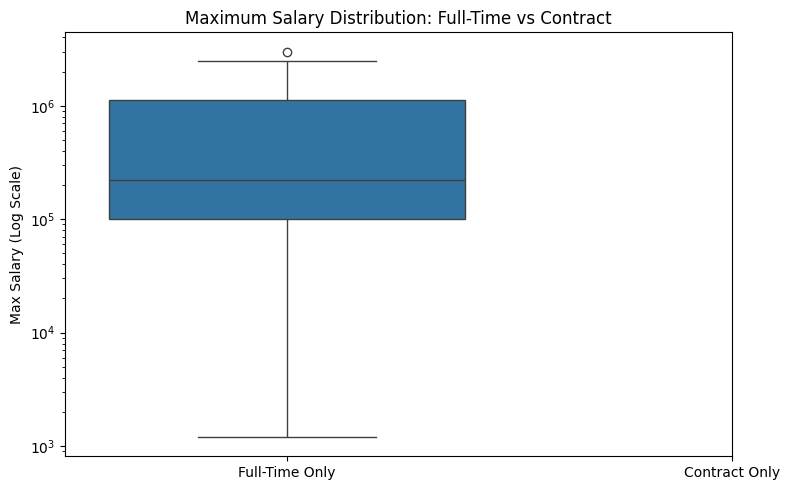

In [47]:
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(data=[full_time_salary, contract_salary])
plt.xticks([0, 1], ['Full-Time Only', 'Contract Only'])
plt.yscale('log')
plt.title('Maximum Salary Distribution: Full-Time vs Contract')
plt.ylabel('Max Salary (Log Scale)')
plt.tight_layout()
plt.show()

**What I did:** I compared the maximum salaries of full-time and contract jobs using the Mann–Whitney U test to check whether there is a significant difference between them.

**Conclusion:** The p-value was 0.0149, which is less than 0.05. This indicates a statistically significant difference in maximum salary distributions between the two job types.

### Final EDA Summary

In this EDA, I explored job postings based on job titles, companies, locations, salaries, job types, and posting dates. I identified popular job titles, companies, and locations, and examined job posting patterns over time. I also checked for missing values and duplicate records and performed a hypothesis test to compare salary distributions between full-time-only and contract-only jobs.

The analysis showed a statistically significant difference in the salary distributions of the two groups. However, salary comparisons should be interpreted carefully because salary units and pay periods need to be verified.

These findings provide a better understanding of the dataset and help identify areas for further analysis and visualization.